# Notebook 1: the HQMM as a Qiskit circuit on a simulator

**Project:** Permutation-Equivariant Hidden Quantum Markov Models for Detecting Market Regime Transitions (Group 15, FDS).

This notebook takes the model we train with our PyTorch engine and runs it as a **gate-level Qiskit circuit** on Qiskit's simulators. No quantum computer and no account are needed.

What it shows, for the generic model (Q-G) and the equivariant model (Q-E):
1. The Kraus operators read out of the Qiskit circuit equal the engine's operators.
2. The log-likelihood of a symbol sequence from the circuit equals the engine's.
3. Shot sampling with real mid-circuit measurement on Aer reproduces the exact outcome probabilities.
4. **Proposition 1 at circuit level:** relabelling the assets does not change the Q-E circuit's likelihood.
5. How many qubits and gates the circuit needs.

The circuit and the checks come from `models/hqmm/qiskit_backend.py`. The model is trained on a small synthetic market with a tiny training budget, so the point is the agreement between the two implementations, not the forecasting quality.

In [1]:
# --- setup: find (or clone) the repo and make sure the packages are installed ---
import importlib, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/Sarahsusangeorge/fds-eqhqmm"
BRANCH = "sarah/qiskit-backend"          # change to "main" once the Qiskit branch is merged

def has_repo(p):
    return (p / "models" / "hqmm" / "qiskit_backend.py").exists()

root = pathlib.Path.cwd()
if not has_repo(root):
    if has_repo(root.parent):
        root = root.parent
    else:
        subprocess.run(["git", "clone", "--depth", "1", "-b", BRANCH, REPO_URL, "fds-eqhqmm"], check=True)
        root = pathlib.Path("fds-eqhqmm").resolve()
os.chdir(root)
sys.path.insert(0, str(root))

need = {"qiskit": "qiskit", "qiskit_aer": "qiskit-aer", "torch": "torch", "scipy": "scipy",
        "pandas": "pandas", "yaml": "pyyaml", "sklearn": "scikit-learn", "matplotlib": "matplotlib"}
missing = [pip for mod, pip in need.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
print("repo:", root)


repo: /tmp/claude-0/-home-claude/5eecb312-ddfd-5008-99e7-acf20aaac6b0/scratchpad/wt


In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from models.base import Fold
from models.hqmm import qiskit_backend as qb
from models.hqmm.engine import LBFGSConfig, register_kraus_table, unitary_columns
from models.hqmm.equivariant import EquivariantBuilder
from models.hqmm.generic import GenericBuilder
from models.hqmm.model import HQMMModel
from tests.helpers import fake_market


def make_model(kind, K=3, fast=True):
    cfg = LBFGSConfig(rounds=2, max_iter=3) if fast else LBFGSConfig()
    if kind == "qe":
        return HQMMModel(lambda n: EquivariantBuilder(2, n, layers=2), K=K, name="Q-E", n_restarts=1,
                         shared_measurement=True, symbol_mode="train_vol", config=cfg)
    return HQMMModel(lambda n: GenericBuilder(2, n, layers=3), K=K, name="Q-G", n_restarts=1,
                     shared_measurement=False, symbol_mode="train_vol", config=cfg)


def fit(kind, n_assets, T=1700, seed=0):
    md, _ = fake_market(T=T, n=n_assets, seed=seed)
    T = md.T                      # a few days are lost to the feature warm-up
    n_tr, n_va = int(T * 0.6), int(T * 0.75)
    fold = Fold(0, np.arange(n_tr), np.arange(n_tr, n_va), np.arange(n_va, T))
    sym0 = np.zeros((T, md.n), dtype=int)
    m = make_model(kind).fit(md, sym0, fold, seed=seed)
    return m, md, fold, sym0


def exact_table(model, n_assets):
    with torch.no_grad():
        return register_kraus_table(unitary_columns(model.builder), model.measurement.rows(), 2, n_assets).numpy()

import qiskit, qiskit_aer
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)
N = 3        # assets in the basket (the number of qubits grows with N)
K = 3        # symbols per asset: down / ordinary / up


qiskit 2.5.2 | qiskit-aer 0.17.2


## 1. Train the two models (small budget, about a minute)

In [3]:
models = {}
for kind in ("qg", "qe"):
    models[kind] = fit(kind, N)
    print(models[kind][0].name, "trained")


Q-G trained


Q-E trained


## 2. One trading day as a circuit

Qubits: the 2 register qubits, the N asset qubits, and 2 readout ancilla qubits per asset. `V` is the model's unitary; each `read` block turns an asset qubit into its symbol, which is measured into the classical bits.

In [4]:
m_e, md_e, fold_e, sym_e = models["qe"]
qc = qb.build_step_circuit(m_e.builder, m_e.measurement, 2, N)
print(qc.draw("text", fold=110))


         ┌────┐                                                
  reg_0: ┤4   ├────────────────────────────────────────────────
         │    │                                                
  reg_1: ┤3   ├────────────────────────────────────────────────
         │    │┌────────┐                                      
asset_0: ┤2 V ├┤2       ├──────────────────────────────────────
         │    ││        │┌────────┐                            
asset_1: ┤1   ├┤        ├┤2       ├────────────────────────────
         │    ││        ││        │┌────────┐                  
asset_2: ┤0   ├┤  read0 ├┤        ├┤2       ├──────────────────
         └────┘│        ││        ││        │┌─┐               
 anc0_0: ──────┤1       ├┤        ├┤        ├┤M├───────────────
               │        ││  read1 ││        │└╥┘┌─┐            
 anc0_1: ──────┤0       ├┤        ├┤        ├─╫─┤M├────────────
               └────────┘│        ││        │ ║ └╥┘┌─┐         
 anc1_0: ────────────────┤1       ├┤  re

## 3. Checks 1 and 2: Kraus operators and log-likelihood

In [5]:
def loglik(table, Y, K, n_register=2):
    dR = 2 ** n_register
    rho, ll = np.eye(dR, dtype=complex) / dR, 0.0
    for y in Y:
        j = 0
        for s in y:
            j = j * K + int(s)
        rho = table[j] @ rho @ table[j].conj().T
        p = np.trace(rho).real
        ll += np.log(p)
        rho = rho / p
    return ll

rows = []
for kind, (m, md, fold, sym0) in models.items():
    ref = exact_table(m, N)
    got = qb.kraus_table_from_circuit(m.builder, m.measurement, 2, N)
    Y = m._symbols(md, sym0)[fold.test_idx][:250]
    rows.append((m.name, np.abs(got - ref).max(), loglik(ref, Y, K), loglik(got, Y, K)))
print(f"{'model':6s} {'max |Kraus diff|':>18s} {'loglik engine':>15s} {'loglik Qiskit':>15s}")
for r in rows:
    print(f"{r[0]:6s} {r[1]:18.2e} {r[2]:15.4f} {r[3]:15.4f}")
assert all(r[1] < 1e-6 for r in rows), "circuit and engine disagree"


model    max |Kraus diff|   loglik engine   loglik Qiskit
Q-G              1.43e-16       -759.9113       -759.9113
Q-E              1.56e-10       -779.7119       -779.7119


## 4. Check 3: shots with mid-circuit measurement on Aer

The circuit is run 20,000 times. The frequency of each outcome (one symbol per asset) is compared with the exact probability from the Kraus operators.

largest probability difference: 0.0061


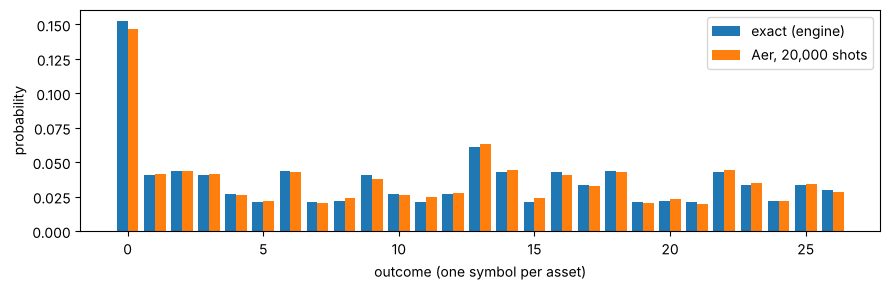

In [6]:
m, md, fold, sym0 = models["qe"]
ref = exact_table(m, N)
rho0 = np.eye(4) / 4
p_exact = np.array([np.trace(ref[y] @ rho0 @ ref[y].conj().T).real for y in range(K ** N)])
S = qb.sample_sequences(m.builder, m.measurement, 2, N, steps=1, shots=20000, seed=1)
y = np.zeros(len(S), int)
for i in range(N):
    y = y * K + S[:, 0, i]
p_aer = np.bincount(y, minlength=K ** N) / len(y)
print("largest probability difference:", round(float(np.abs(p_aer - p_exact).max()), 4))
x = np.arange(K ** N)
plt.figure(figsize=(9, 3))
plt.bar(x - 0.2, p_exact, 0.4, label="exact (engine)")
plt.bar(x + 0.2, p_aer, 0.4, label="Aer, 20,000 shots")
plt.xlabel("outcome (one symbol per asset)"); plt.ylabel("probability"); plt.legend(); plt.tight_layout(); plt.show()


## 5. Check 4: Proposition 1 on the circuit

Shuffle the order of the assets in a symbol sequence. The Q-E circuit's log-likelihood should not move.

In [7]:
m, md, fold, sym0 = models["qe"]
ref = exact_table(m, N)
got = qb.kraus_table_from_circuit(m.builder, m.measurement, 2, N)
Y = m._symbols(md, sym0)[fold.test_idx][:250]
perm = np.random.default_rng(0).permutation(N)
print("permutation:", perm)
print("log-likelihood, original order  :", round(loglik(got, Y, K), 6))
print("log-likelihood, relabelled order:", round(loglik(got, Y[:, perm], K), 6))
mg, mdg, fg, sg = models["qg"]
gg = qb.kraus_table_from_circuit(mg.builder, mg.measurement, 2, N)
Yg = mg._symbols(mdg, sg)[fg.test_idx][:250]
print("for comparison, the generic Q-G circuit: ", round(loglik(gg, Yg, K), 6), "->", round(loglik(gg, Yg[:, perm], K), 6))


permutation: [2 0 1]
log-likelihood, original order  : -779.711902
log-likelihood, relabelled order: -779.711902
for comparison, the generic Q-G circuit:  -759.911328 -> -767.28699


## 6. Resources

Circuit size after compiling to the basic gates `rz, sx, x, cx` (an upper bound; a real compiler would do better).

In [8]:
for kind, (m, md, fold, sym0) in models.items():
    res = qb.circuit_resources(qb.build_step_circuit(m.builder, m.measurement, 2, N))
    print(f"{m.name}: {res['qubits']} qubits, {res['cx']} CX gates, depth {res['depth']}")


Q-G: 11 qubits, 480 CX gates, depth 1635
Q-E: 11 qubits, 480 CX gates, depth 1669


## What this shows

The Qiskit circuit is the same model as the PyTorch engine: same operators, same likelihood, same outcome frequencies, and the symmetry result holds on the circuit. The simulator is exact, so this is a correctness check, not evidence about hardware. Notebook 2 runs a small version on Azure Quantum.